In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("prasunroy/natural-images")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\rarap\.cache\kagglehub\datasets\prasunroy\natural-images\versions\1


In [2]:
from pathlib import Path

root = Path(path)

print("Contenu du dossier téléchargé :")
for item in sorted(root.iterdir()):
    print(f"- {item.name}")

Contenu du dossier téléchargé :
- data
- natural_images


In [3]:
import pandas as pd

data_dir = root / "natural_images"
extensions = {".jpg", ".jpeg", ".png"}

counts = pd.Series({
    folder.name: sum(
        file.is_file() and file.suffix.lower() in extensions
        for file in folder.iterdir()
    )
    for folder in sorted(data_dir.iterdir())
    if folder.is_dir()
}, name="Nombre d’images").sort_values(ascending=False)

display(counts.to_frame())
print(f"Total : {counts.sum():,} images")

,Nombre d’images
fruit,1000
person,986
car,968
cat,885
flower,843
motorbike,788
airplane,727
dog,702


Total : 6,899 images


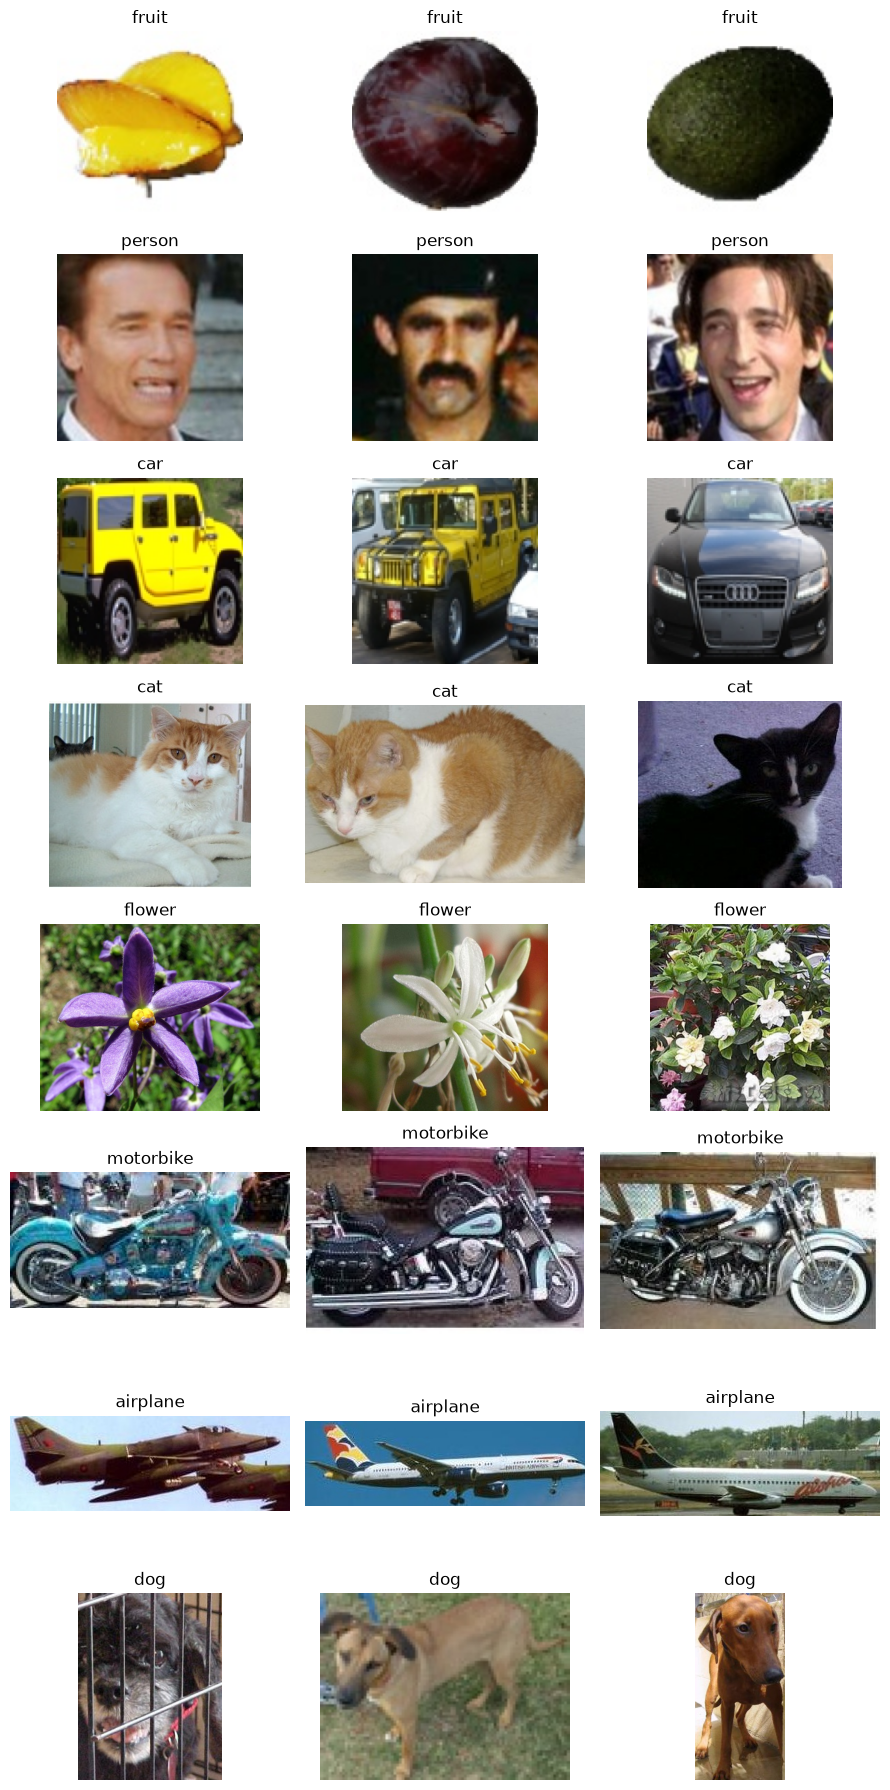

In [4]:
import random
import matplotlib.pyplot as plt
from PIL import Image

rng = random.Random(2)

fig, axes = plt.subplots(len(counts), 3, figsize=(9, 18))

for row, class_name in enumerate(counts.index):
    files = sorted(
        file for file in (data_dir / class_name).iterdir()
        if file.is_file() and file.suffix.lower() in extensions
    )

    for col, file in enumerate(rng.sample(files, 3)):
        ax = axes[row, col]
        with Image.open(file) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(class_name)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
dimensions = []

for class_name in counts.index:
    for file in (data_dir / class_name).iterdir():
        if file.is_file() and file.suffix.lower() in extensions:
            with Image.open(file) as image:
                width, height = image.size

            dimensions.append({
                "classe": class_name,
                "largeur": width,
                "hauteur": height,
            })

sizes = pd.DataFrame(dimensions)
display(sizes[["largeur", "hauteur"]].describe().round(1))

,largeur,hauteur
count,6899.0,6899.0
mean,234.9,198.2
std,136.0,129.4
min,43.0,50.0
25%,100.0,100.0
50%,231.0,122.0
75%,295.0,256.0
max,2737.0,2665.0


In [6]:
import numpy as np

sizes["ratio"] = sizes["largeur"] / sizes["hauteur"]

sizes["format"] = np.select(
    [sizes["ratio"] < 0.9, sizes["ratio"] > 1.1],
    ["Portrait", "Paysage"],
    default="Quasi carré",
)

display(pd.crosstab(
    sizes["classe"],
    sizes["format"],
    normalize="index",
).mul(100).round(1))

format,Paysage,Portrait,Quasi carré
classe,,,
airplane,99.9,0.1,0.0
car,0.0,0.0,100.0
cat,44.4,34.7,20.9
dog,30.9,48.6,20.5
flower,60.4,19.3,20.3
fruit,0.0,0.0,100.0
motorbike,100.0,0.0,0.0
person,0.0,0.0,100.0


In [7]:
top_sizes = (
    sizes.groupby(["classe", "largeur", "hauteur"])
    .size()
    .reset_index(name="nombre")
    .sort_values(["classe", "nombre"], ascending=[True, False])
)

display(top_sizes.groupby("classe").head(3).reset_index(drop=True))

,classe,largeur,hauteur,nombre
0,airplane,294,89,5
1,airplane,291,89,4
2,airplane,299,96,4
3,car,100,100,968
4,cat,160,189,2
5,cat,426,364,2
6,cat,429,368,2
7,dog,210,247,2
8,dog,43,114,1
9,dog,51,58,1


Certaines classes présentent une résolution d’origine presque uniforme. Toutes les images car et fruit sont en 100 × 100 pixels, tandis que 99,7 % des images person sont en 256 × 256 pixels. Nous testerons un redimensionnement commun à 128 × 128 pixels et visualiserons son effet sur des images carrées, paysage et portrait avant de choisir la méthode de prétraitement.

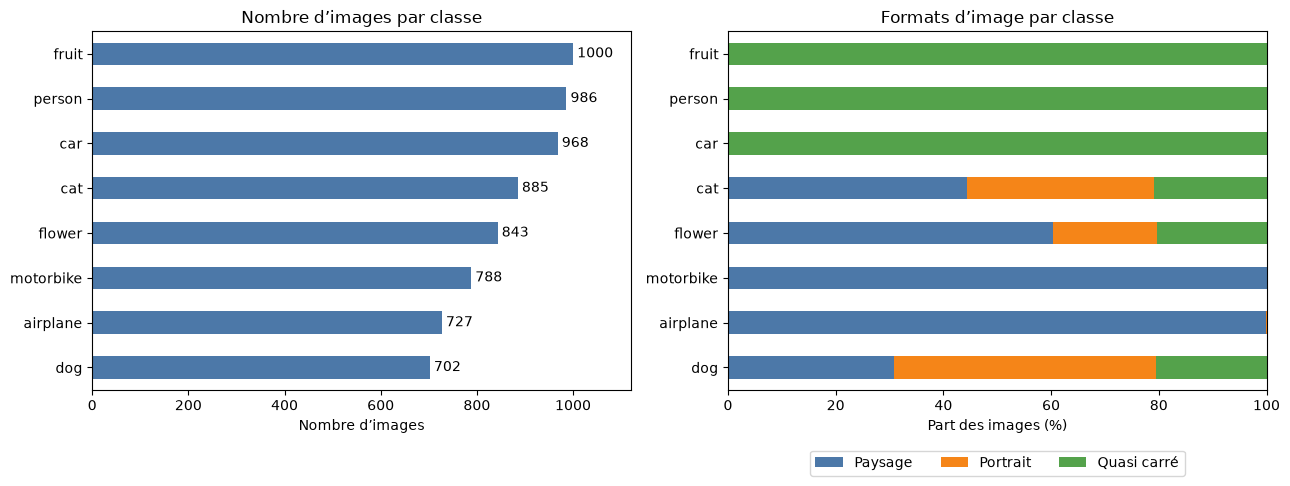

In [8]:
import matplotlib.pyplot as plt

order = counts.index

formats = (
    pd.crosstab(sizes["classe"], sizes["format"], normalize="index")
    .reindex(index=order, columns=["Paysage", "Portrait", "Quasi carré"])
    .mul(100)
)

fig, (ax_counts, ax_formats) = plt.subplots(1, 2, figsize=(13, 5))

counts.plot.barh(ax=ax_counts, color="#4C78A8")
ax_counts.invert_yaxis()
ax_counts.bar_label(ax_counts.containers[0], padding=3)
ax_counts.set_xlim(0, counts.max() * 1.12)
ax_counts.set_title("Nombre d’images par classe")
ax_counts.set_xlabel("Nombre d’images")
ax_counts.set_ylabel("")

formats.plot.barh(
    ax=ax_formats,
    stacked=True,
    color=["#4C78A8", "#F58518", "#54A24B"],
)
ax_formats.invert_yaxis()
ax_formats.set_xlim(0, 100)
ax_formats.set_title("Formats d’image par classe")
ax_formats.set_xlabel("Part des images (%)")
ax_formats.set_ylabel("")
ax_formats.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

plt.tight_layout()
plt.show()

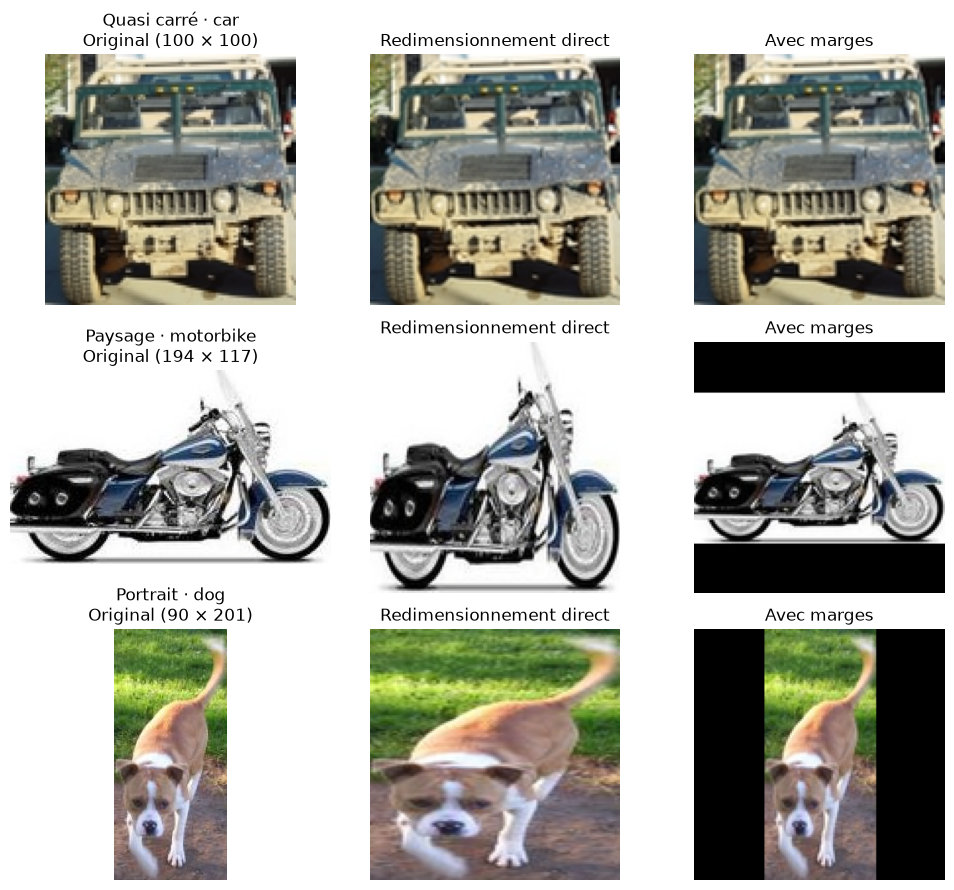

In [9]:
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

target_size = (128, 128)
resampling = Image.Resampling.LANCZOS

selection = [
    ("Quasi carré", "car", lambda ratio: 0.9 <= ratio <= 1.1),
    ("Paysage", "motorbike", lambda ratio: ratio > 1.1),
    ("Portrait", "dog", lambda ratio: ratio < 0.9),
]

fig, axes = plt.subplots(3, 3, figsize=(10, 9))

for row, (format_name, class_name, matches) in enumerate(selection):
    for file in sorted((data_dir / class_name).iterdir()):
        if file.is_file() and file.suffix.lower() in extensions:
            with Image.open(file) as image:
                if matches(image.width / image.height):
                    original = image.convert("RGB")
                    break
    else:
        raise ValueError(f"Aucune image {format_name} trouvée dans {class_name}")

    direct = original.resize(target_size, resampling)
    padded = ImageOps.pad(original, target_size, method=resampling, color="black")

    titles = [
        f"{format_name} · {class_name}\nOriginal ({original.width} × {original.height})",
        "Redimensionnement direct",
        "Avec marges",
    ]

    for ax, image, title in zip(axes[row], [original, direct, padded], titles):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
from pathlib import Path
import shutil

import kagglehub
import pandas as pd

path = kagglehub.dataset_download("prasunroy/natural-images")
data_dir = Path(path) / "natural_images"

splits = pd.read_csv("splits.csv")
folders = {"train": "train", "validation": "valid", "test": "test"}

for _, row in splits.iterrows():
    relative_path = Path(row["relative_path"])
    source = data_dir / relative_path
    destination = Path("data") / folders[row["split"]] / relative_path

    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)